In [1]:
import glob
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

saved = torch.load(glob.glob("/kaggle/input/**/slices_224.pt", recursive=True)[0])
X, y = saved["X"].float(), saved["y"]

csv_path = glob.glob("/kaggle/input/**/*slice_info*.csv", recursive=True)[0]
df = pd.read_csv(csv_path, dtype={"slice_id": str, "pid": str})
if "slice_ids" in saved:
    df = df.set_index("slice_id").loc[saved["slice_ids"]].reset_index()

assert len(df) == len(X) == len(y)
assert (df["label"].to_numpy() - 1 == y.numpy()).all(), "rows of X and the CSV don't line up"
idx = {s: np.where(df["split"] == s)[0] for s in ["train", "val", "test"]}
print({k: len(v) for k, v in idx.items()})

device: cuda
{'train': 2449, 'val': 365, 'test': 250}


In [2]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
augment = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.RandomRotation(10)])

class SliceDataset(Dataset):
    def __init__(self, indices, train):
        self.indices, self.train = indices, train
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]
        x = augment(X[j]) if self.train else X[j]
        return (x.repeat(3, 1, 1) - MEAN) / STD, y[j]

def predict(model, indices):
    dl = DataLoader(SliceDataset(indices, False), batch_size=64)
    model.eval()
    out = []
    with torch.no_grad():
        for xb, _ in dl:
            out.append(F.softmax(model(xb.to(device)), dim=1).cpu())
    return torch.cat(out).numpy()

def accuracy(probs, indices):
    return float((probs.argmax(1) == y[indices].numpy()).mean())

def train_model(train_idx, eval_idx, epochs=8, seed=0, lr=1e-4):
    torch.manual_seed(seed); np.random.seed(seed)
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, 3)
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    dl = DataLoader(SliceDataset(train_idx, True), batch_size=32, shuffle=True, num_workers=2)
    best_acc, best_state = 0.0, None
    for epoch in range(epochs):
        model.train()
        for xb, yb in dl:
            opt.zero_grad()
            loss_fn(model(xb.to(device)), yb.to(device)).backward()
            opt.step()
        acc = accuracy(predict(model, eval_idx), eval_idx)
        if acc > best_acc:
            best_acc = acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, best_acc

In [3]:
SEEDS = [0, 1, 2]        # about 20-30 minutes on a GPU; use [0] for a quick first try

pool = np.concatenate([idx["train"], idx["val"]])          # test patients stay out
frac = len(idx["val"]) / len(pool)
labels = df["label"].to_numpy()

def slice_level_split(pool, holdout_frac, seed):
    rng = np.random.default_rng(seed)
    tr, ho = [], []
    for label in [1, 2, 3]:
        ids = rng.permutation(pool[labels[pool] == label])
        n_ho = round(holdout_frac * len(ids))
        ho += list(ids[:n_ho]); tr += list(ids[n_ho:])
    return np.array(tr), np.array(ho)

results = []
for seed in SEEDS:
    # A: patient-level split
    mA, accA = train_model(idx["train"], idx["val"], seed=seed)
    testA = accuracy(predict(mA, idx["test"]), idx["test"])

    # B: random slice-level split
    tr_B, ho_B = slice_level_split(pool, frac, seed)
    seen = set(df["pid"].iloc[tr_B])
    overlap = float(np.mean([p in seen for p in df["pid"].iloc[ho_B]]))
    mB, accB = train_model(tr_B, ho_B, seed=seed)
    testB = accuracy(predict(mB, idx["test"]), idx["test"])

    results.append({"seed": seed,
                    "patient_heldout": accA, "slice_heldout": accB,
                    "slice_overlap": overlap,
                    "patient_on_test": testA, "slice_on_test": testB})
    print(f"seed {seed} done:", {k: round(v, 3) for k, v in results[-1].items() if k != "seed"})

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 248MB/s]


seed 0 done: {'patient_heldout': 0.937, 'slice_heldout': 0.978, 'slice_overlap': 0.997, 'patient_on_test': 0.96, 'slice_on_test': 0.948}
seed 1 done: {'patient_heldout': 0.94, 'slice_heldout': 0.975, 'slice_overlap': 0.997, 'patient_on_test': 0.972, 'slice_on_test': 0.94}
seed 2 done: {'patient_heldout': 0.937, 'slice_heldout': 0.981, 'slice_overlap': 0.986, 'patient_on_test': 0.956, 'slice_on_test': 0.964}


 seed  patient_heldout  slice_heldout  slice_overlap  patient_on_test  slice_on_test
    0            0.937          0.978          0.997            0.960          0.948
    1            0.940          0.975          0.997            0.972          0.940
    2            0.937          0.981          0.986            0.956          0.964
                  mean    min    max
patient_heldout  0.938  0.937  0.940
slice_heldout    0.978  0.975  0.981
slice_overlap    0.994  0.986  0.997
patient_on_test  0.963  0.956  0.972
slice_on_test    0.951  0.940  0.964


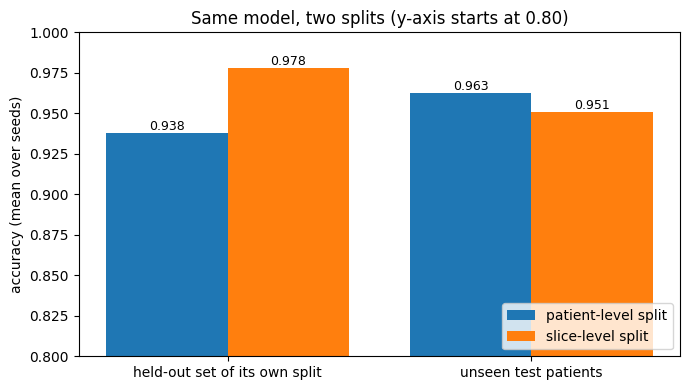

In [4]:
res = pd.DataFrame(results)
print(res.round(3).to_string(index=False))
print(res.drop(columns="seed").agg(["mean", "min", "max"]).round(3).T)
res.to_csv("/kaggle/working/leakage_results.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
xs = np.arange(2)
a = [res.patient_heldout.mean(), res.patient_on_test.mean()]
b = [res.slice_heldout.mean(), res.slice_on_test.mean()]
ax.bar(xs - 0.2, a, 0.4, label="patient-level split")
ax.bar(xs + 0.2, b, 0.4, label="slice-level split")
for x, v in zip(xs - 0.2, a): ax.text(x, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
for x, v in zip(xs + 0.2, b): ax.text(x, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
ax.set_xticks(xs)
ax.set_xticklabels(["held-out set of its own split", "unseen test patients"])
ax.set_ylim(0.8, 1.0)
ax.set_ylabel("accuracy (mean over seeds)")
ax.set_title("Same model, two splits (y-axis starts at 0.80)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("/kaggle/working/leakage_experiment.png", dpi=150)
plt.show()